# Mod_C
## Week 3

### Cardovascular Disease


- Forward Selection
- Backward Selection
- Principal Component Regression (PCR)
- Partial Least Squares Regression (PLSR)

The analysis will continue using the Statlog Heart Disease and Framingham Heart Study datasets.

For Statlog, maximum heart rate (`thalach`) will remain the continuous outcome. For Framingham,
systolic blood pressure (`sysBP`) will remain the continuous outcome.

Model selection will be based primarily on 5-fold cross-validation RMSE. Testing R² and testing
RMSE will then be used to evaluate how well the selected models generalize to unseen data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [5]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham (1).csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease (1).csv


In [38]:
heart = pd.read_csv("/content/preprocessed_heart_disease.csv")
framingham = pd.read_csv("/content/preprocessed_framingham.csv")

print("Heart Disease dataset shape:", heart.shape)
print("Framingham dataset shape:", framingham.shape)

Heart Disease dataset shape: (270, 14)
Framingham dataset shape: (4238, 16)


I'm using the same predictors and continuous outcomes from prev weeks

### Statlog Heart Disease

Outcome:

- `thalach` = maximum heart rate achieved

Predictors:

- age
- sex
- resting blood pressure (`trestbps`)
- cholesterol (`chol`)
- fasting blood sugar (`fbs`)
- exercise-induced angina (`exang`)
- ST depression (`oldpeak`)

### Framingham Heart Study

Outcome:

- `sysBP` = systolic blood pressure

Predictors:

- male
- age
- currentSmoker
- cigsPerDay
- BPMeds
- prevalentStroke
- diabetes
- totChol
- BMI
- heartRate
- glucose

Same modeling problems as Week 2 so its easier to compare how feature selection and
dimensionality reduction affect the models.

In [39]:
heart_predictors = [
    "age",
    "sex",
    "trestbps",
    "chol",
    "fbs",
    "exang",
    "oldpeak"
]

framingham_predictors = [
    "male",
    "age",
    "currentSmoker",
    "cigsPerDay",
    "BPMeds",
    "prevalentStroke",
    "diabetes",
    "totChol",
    "BMI",
    "heartRate",
    "glucose"
]

## Train-Test Separation

To avoid data leakage, the data will be divided into training and testing sets before forward and
backward feature selection is performed.

Feature selection will be performed using only the training data. Five-fold cross-validation within
the training data will determine the preferred feature subset.

The held-out test data will not be used during feature selection and will only be used afterward to
evaluate how well the selected model generalizes to unseen observations.

In [40]:
# Statlog train-test split

heart_stepwise_data = heart[
    heart_predictors + ["thalach"]
].dropna()

X_heart_full = heart_stepwise_data[
    heart_predictors
]

y_heart_full = heart_stepwise_data[
    "thalach"
]

X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart_full,
    y_heart_full,
    test_size=0.20,
    random_state=42
)


# Framingham train-test split

framingham_stepwise_data = framingham[
    framingham_predictors + ["sysBP"]
].dropna()

X_framingham_full = framingham_stepwise_data[
    framingham_predictors
]

y_framingham_full = framingham_stepwise_data[
    "sysBP"
]

X_framingham_train, X_framingham_test, y_framingham_train, y_framingham_test = train_test_split(
    X_framingham_full,
    y_framingham_full,
    test_size=0.20,
    random_state=42
)

print("Training and testing sets created successfully.")

Training and testing sets created successfully.


## Forward Selection

No predictors.

At each step, every remaining predictor is tested and the predictor that produces the best model
is added. The process then repeats using the predictors already selected plus one additional feature.

This does not examine every possible combination of predictors. Instead, it follows one path based
on the best choice available at each step.

In this analysis, 5-fold cross-validation RMSE will be used to decide which predictor should be
added at each stage. Lower cross-validation RMSE indicates better predictive performance.


In [41]:
def forward_selection(X, y):

    selected = []
    remaining = list(X.columns)

    history = []

    while remaining:

        candidates = []

        for feature in remaining:

            trial_features = selected + [feature]

            model = LinearRegression()

            cv_scores = -cross_val_score(
                model,
                X[trial_features],
                y,
                cv=5,
                scoring="neg_root_mean_squared_error"
            )

            candidates.append({
                "Added Feature": feature,
                "CV RMSE": cv_scores.mean()
            })

        candidate_df = pd.DataFrame(candidates)

        best_row = candidate_df.loc[
            candidate_df["CV RMSE"].idxmin()
        ]

        best_feature = best_row["Added Feature"]
        best_rmse = best_row["CV RMSE"]

        selected.append(best_feature)
        remaining.remove(best_feature)

        history.append({
            "Number of Features": len(selected),
            "Feature Added": best_feature,
            "Selected Features": ", ".join(selected),
            "CV RMSE": best_rmse
        })

    history_df = pd.DataFrame(history)

    best_index = history_df["CV RMSE"].idxmin()

    best_features = history_df.loc[
        best_index,
        "Selected Features"
    ].split(", ")

    return history_df.round(3), best_features

### Statlog Forward Selection

Forward selection will determine which combo of statlog preds produces the lowest
5-fold cross-validation RMSE.

In [42]:
heart_forward_history, heart_forward_features = forward_selection(
    X_heart_train,
    y_heart_train
)

display(heart_forward_history)

print("Best Statlog feature subset:")
print(heart_forward_features)

,Number of Features,Feature Added,Selected Features,CV RMSE
0,1,exang,exang,20.779
1,2,age,"exang, age",18.925
2,3,oldpeak,"exang, age, oldpeak",18.643
3,4,trestbps,"exang, age, oldpeak, trestbps",18.570
4,5,sex,"exang, age, oldpeak, trestbps, sex",18.541
5,6,chol,"exang, age, oldpeak, trestbps, sex, chol",18.577
6,7,fbs,"exang, age, oldpeak, trestbps, sex, chol, fbs",18.809


Best Statlog feature subset:
['exang', 'age', 'oldpeak', 'trestbps', 'sex']


### Framingham Forward Selection

The same forward-selection procedure will be applied to the Framingham predictors.

In [43]:
framingham_forward_history, framingham_forward_features = forward_selection(
    X_framingham_train,
    y_framingham_train
)

display(framingham_forward_history)

print("Best Framingham feature subset:")
print(framingham_forward_features)

,Number of Features,Feature Added,Selected Features,CV RMSE
0,1,age,age,20.329
1,2,BMI,"age, BMI",19.330
2,3,BPMeds,"age, BMI, BPMeds",18.881
3,4,heartRate,"age, BMI, BPMeds, heartRate",18.533
4,5,totChol,"age, BMI, BPMeds, heartRate, totChol",18.480
5,6,glucose,"age, BMI, BPMeds, heartRate, totChol, glucose",18.461
6,7,male,"age, BMI, BPMeds, heartRate, totChol, glucose,...",18.461
7,8,currentSmoker,"age, BMI, BPMeds, heartRate, totChol, glucose,...",18.462
8,9,cigsPerDay,"age, BMI, BPMeds, heartRate, totChol, glucose,...",18.464
9,10,diabetes,"age, BMI, BPMeds, heartRate, totChol, glucose,...",18.470


Best Framingham feature subset:
['age', 'BMI', 'BPMeds', 'heartRate', 'totChol', 'glucose', 'male']


## Backward Selection

Backward selection

Begins with all available preds and removes one predctr at a time. At each stage, the
feature whose removal produces the best cross-val performance is removed.

The process continues until only 1 predictor is there.

The model with the lowest 5-fold cross-validation RMSE along the backward-selection path will be
treated as the preferred subset.

In [44]:
def backward_selection(X, y):

    selected = list(X.columns)

    history = []

    # Evaluate the full model first
    full_model = LinearRegression()

    full_cv = -cross_val_score(
        full_model,
        X[selected],
        y,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    history.append({
        "Number of Features": len(selected),
        "Feature Removed": "None",
        "Selected Features": ", ".join(selected),
        "CV RMSE": full_cv.mean()
    })

    while len(selected) > 1:

        candidates = []

        for feature in selected:

            trial_features = [
                f for f in selected
                if f != feature
            ]

            model = LinearRegression()

            cv_scores = -cross_val_score(
                model,
                X[trial_features],
                y,
                cv=5,
                scoring="neg_root_mean_squared_error"
            )

            candidates.append({
                "Removed Feature": feature,
                "CV RMSE": cv_scores.mean()
            })

        candidate_df = pd.DataFrame(candidates)

        best_row = candidate_df.loc[
            candidate_df["CV RMSE"].idxmin()
        ]

        feature_to_remove = best_row[
            "Removed Feature"
        ]

        best_rmse = best_row["CV RMSE"]

        selected.remove(feature_to_remove)

        history.append({
            "Number of Features": len(selected),
            "Feature Removed": feature_to_remove,
            "Selected Features": ", ".join(selected),
            "CV RMSE": best_rmse
        })

    history_df = pd.DataFrame(history)

    best_index = history_df["CV RMSE"].idxmin()

    best_features = history_df.loc[
        best_index,
        "Selected Features"
    ].split(", ")

    return history_df.round(3), best_features

### Statlog Backward Selection

In [45]:
heart_backward_history, heart_backward_features = backward_selection(
    X_heart_train,
    y_heart_train
)

display(heart_backward_history)

print("Best Statlog feature subset:")
print(heart_backward_features)

,Number of Features,Feature Removed,Selected Features,CV RMSE
0,7,None,"age, sex, trestbps, chol, fbs, exang, oldpeak",18.809
1,6,fbs,"age, sex, trestbps, chol, exang, oldpeak",18.577
2,5,chol,"age, sex, trestbps, exang, oldpeak",18.541
3,4,sex,"age, trestbps, exang, oldpeak",18.570
4,3,trestbps,"age, exang, oldpeak",18.643
5,2,oldpeak,"age, exang",18.925
6,1,age,exang,20.779


Best Statlog feature subset:
['age', 'sex', 'trestbps', 'exang', 'oldpeak']


### Framingham Backward Selection

In [46]:
framingham_backward_history, framingham_backward_features = backward_selection(
    X_framingham_train,
    y_framingham_train
)

display(framingham_backward_history)

print("Best Framingham feature subset:")
print(framingham_backward_features)

,Number of Features,Feature Removed,Selected Features,CV RMSE
0,11,None,"male, age, currentSmoker, cigsPerDay, BPMeds, ...",18.485
1,10,prevalentStroke,"male, age, currentSmoker, cigsPerDay, BPMeds, ...",18.470
2,9,diabetes,"male, age, currentSmoker, cigsPerDay, BPMeds, ...",18.464
3,8,cigsPerDay,"male, age, currentSmoker, BPMeds, totChol, BMI...",18.462
4,7,currentSmoker,"male, age, BPMeds, totChol, BMI, heartRate, gl...",18.461
5,6,male,"age, BPMeds, totChol, BMI, heartRate, glucose",18.461
6,5,glucose,"age, BPMeds, totChol, BMI, heartRate",18.480
7,4,totChol,"age, BPMeds, BMI, heartRate",18.533
8,3,heartRate,"age, BPMeds, BMI",18.881
9,2,BPMeds,"age, BMI",19.330


Best Framingham feature subset:
['male', 'age', 'BPMeds', 'totChol', 'BMI', 'heartRate', 'glucose']


## Forward vs Backward Selection

The following figures show how cross-validation RMSE changes as predictors are added during
forward selection or removed during backward selection.

The lowest point represents the strongest cross-validation performance found along each selection path.

In [47]:
def plot_selection_paths(
    forward_history,
    backward_history,
    dataset_name
):

    plt.figure(figsize=(8, 5))

    plt.plot(
        forward_history["Number of Features"],
        forward_history["CV RMSE"],
        marker="o",
        label="Forward Selection"
    )

    plt.plot(
        backward_history["Number of Features"],
        backward_history["CV RMSE"],
        marker="o",
        label="Backward Selection"
    )

    plt.xlabel("Number of Predictors")
    plt.ylabel("5-Fold CV RMSE")
    plt.title(
        f"{dataset_name}: Forward vs Backward Selection"
    )

    plt.legend()
    plt.show()

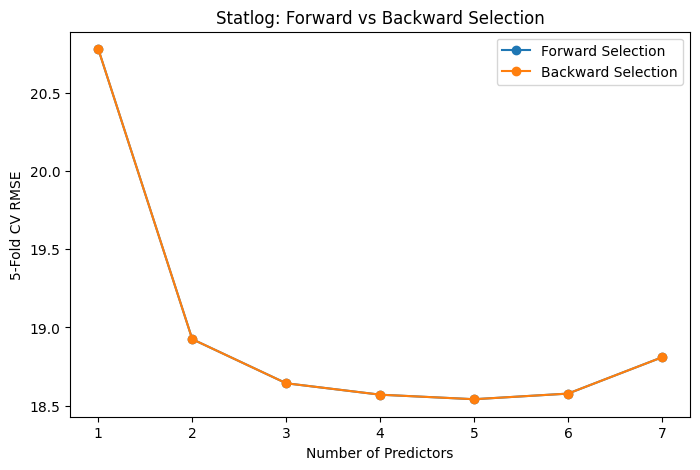

In [48]:
plot_selection_paths(
    heart_forward_history,
    heart_backward_history,
    "Statlog"
)

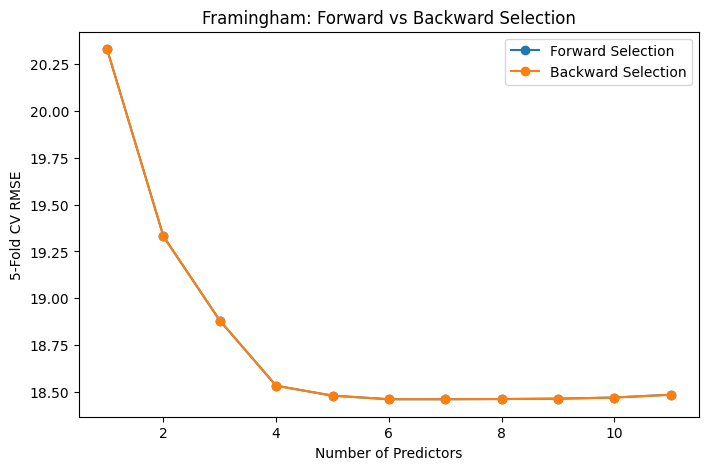

In [49]:
plot_selection_paths(
    framingham_forward_history,
    framingham_backward_history,
    "Framingham"
)

## Evaluation of Selected Feature Subsets

Forward and backward selection identify predictor subsets using cross-validation.

To determine whether the selected subsets generalize to unseen observations, each selected model
will now be evaluated using an 80/20 train-test split.

The same random state will be used for all models to make the comparisons consistent.

In [50]:
def evaluate_selected_model(
    X_train,
    X_test,
    y_train,
    y_test,
    predictors,
    dataset_name,
    selection_name
):

    model = LinearRegression()

    model.fit(
        X_train[predictors],
        y_train
    )

    train_predictions = model.predict(
        X_train[predictors]
    )

    test_predictions = model.predict(
        X_test[predictors]
    )

    results = {
        "Dataset": dataset_name,
        "Method": selection_name,
        "Number of Predictors": len(predictors),

        "Training R²": r2_score(
            y_train,
            train_predictions
        ),

        "Testing R²": r2_score(
            y_test,
            test_predictions
        ),

        "Testing RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                test_predictions
            )
        )
    }

    return results

### Statlog Selected Models

In [51]:
heart_forward_evaluation = evaluate_selected_model(
    X_heart_train,
    X_heart_test,
    y_heart_train,
    y_heart_test,
    heart_forward_features,
    "Statlog",
    "Forward Selection"
)

heart_backward_evaluation = evaluate_selected_model(
    X_heart_train,
    X_heart_test,
    y_heart_train,
    y_heart_test,
    heart_backward_features,
    "Statlog",
    "Backward Selection"
)

heart_selection_results = pd.DataFrame([
    heart_forward_evaluation,
    heart_backward_evaluation
]).round(3)

display(heart_selection_results)

,Dataset,Method,Number of Predictors,Training R²,Testing R²,Testing RMSE
0,Statlog,Forward Selection,5,0.362,0.184,21.797
1,Statlog,Backward Selection,5,0.362,0.184,21.797


### Framingham Selected Models

In [52]:
framingham_forward_evaluation = evaluate_selected_model(
    X_framingham_train,
    X_framingham_test,
    y_framingham_train,
    y_framingham_test,
    framingham_forward_features,
    "Framingham",
    "Forward Selection"
)

framingham_backward_evaluation = evaluate_selected_model(
    X_framingham_train,
    X_framingham_test,
    y_framingham_train,
    y_framingham_test,
    framingham_backward_features,
    "Framingham",
    "Backward Selection"
)

framingham_selection_results = pd.DataFrame([
    framingham_forward_evaluation,
    framingham_backward_evaluation
]).round(3)

display(framingham_selection_results)

,Dataset,Method,Number of Predictors,Training R²,Testing R²,Testing RMSE
0,Framingham,Forward Selection,7,0.308,0.259,18.691
1,Framingham,Backward Selection,7,0.308,0.259,18.691


## Full Linear Regression Baseline

To evaluate whether feature selection provides a benefit, the selected models will be compared with
ordinary linear regression using all available predictors.

This provides a baseline for determining whether reducing the number of predictors improves
generalization, maintains similar performance with a simpler model, or reduces predictive accuracy.

In [53]:
heart_full_evaluation = evaluate_selected_model(
    X_heart_train,
    X_heart_test,
    y_heart_train,
    y_heart_test,
    heart_predictors,
    "Statlog",
    "Full Linear Regression"
)

framingham_full_evaluation = evaluate_selected_model(
    X_framingham_train,
    X_framingham_test,
    y_framingham_train,
    y_framingham_test,
    framingham_predictors,
    "Framingham",
    "Full Linear Regression"
)

baseline_results = pd.DataFrame([
    heart_full_evaluation,
    framingham_full_evaluation
]).round(3)

display(baseline_results)

,Dataset,Method,Number of Predictors,Training R²,Testing R²,Testing RMSE
0,Statlog,Full Linear Regression,7,0.365,0.198,21.616
1,Framingham,Full Linear Regression,11,0.309,0.259,18.685


## Principal Component Regression (PCR)

Principal Component Regression first applies Principal Component Analysis (PCA) to the predictors.

Instead of using the original variables directly, PCA combines them into new variables called
principal components. These components are ordered according to how much variation in the predictor
data they explain.

Linear regression is then performed using a selected number of principal components.

The predictors will be standardized before PCA so variables measured on larger numerical scales do
not dominate the components.

Using every principal component would retain essentially all of the information in the original
predictors. Therefore, cross-validation will be used to determine whether using fewer components can
produce a simpler model with similar or better predictive performance.

A limitation of PCR is that PCA creates components based on variation in the predictors without
considering the outcome variable. A component may explain substantial predictor variance while still
being unimportant for prediction.

In [54]:
def run_pcr_analysis(df, predictors, target, dataset_name):

    data = df[predictors + [target]].dropna()

    X = data[predictors]
    y = data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    component_results = []

    max_components = len(predictors)

    for n_components in range(
        1,
        max_components + 1
    ):

        pcr_model = Pipeline([
            (
                "scale",
                StandardScaler()
            ),
            (
                "pca",
                PCA(
                    n_components=n_components
                )
            ),
            (
                "regression",
                LinearRegression()
            )
        ])

        cv_scores = -cross_val_score(
            pcr_model,
            X_train,
            y_train,
            cv=5,
            scoring="neg_root_mean_squared_error"
        )

        component_results.append({
            "Components": n_components,
            "CV RMSE": cv_scores.mean()
        })

    component_df = pd.DataFrame(
        component_results
    )

    best_components = int(
        component_df.loc[
            component_df["CV RMSE"].idxmin(),
            "Components"
        ]
    )

    best_model = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "pca",
            PCA(
                n_components=best_components
            )
        ),
        (
            "regression",
            LinearRegression()
        )
    ])

    best_model.fit(
        X_train,
        y_train
    )

    train_predictions = best_model.predict(
        X_train
    )

    test_predictions = best_model.predict(
        X_test
    )

    evaluation = pd.DataFrame([{
        "Dataset": dataset_name,
        "Best Components": best_components,
        "Training R²": r2_score(
            y_train,
            train_predictions
        ),
        "Testing R²": r2_score(
            y_test,
            test_predictions
        ),
        "Testing RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                test_predictions
            )
        )
    }])

    return (
        component_df.round(3),
        evaluation.round(3),
        best_model
    )

### Statlog PCR

In [55]:
heart_pcr_components, heart_pcr_results, heart_pcr_model = run_pcr_analysis(
    heart,
    heart_predictors,
    "thalach",
    "Statlog"
)

display(heart_pcr_components)
display(heart_pcr_results)

,Components,CV RMSE
0,1,20.834
1,2,19.548
2,3,19.753
3,4,19.486
4,5,19.035
5,6,18.902
6,7,18.809


,Dataset,Best Components,Training R²,Testing R²,Testing RMSE
0,Statlog,7,0.365,0.198,21.616


### Framingham PCR

In [56]:
framingham_pcr_components, framingham_pcr_results, framingham_pcr_model = run_pcr_analysis(
    framingham,
    framingham_predictors,
    "sysBP",
    "Framingham"
)

display(framingham_pcr_components)
display(framingham_pcr_results)

,Components,CV RMSE
0,1,20.934
1,2,20.556
2,3,18.971
3,4,18.956
4,5,18.952
5,6,18.851
6,7,18.843
7,8,18.686
8,9,18.470
9,10,18.480


,Dataset,Best Components,Training R²,Testing R²,Testing RMSE
0,Framingham,9,0.309,0.259,18.693


## Partial Least Squares Regression (PLSR)

PLSR also reduces the predictors into a smaller number of components.

The major difference from PCR is that PLSR uses information about the outcome while constructing
its components.

PCR searches for directions that explain large amounts of variation in the predictors.

PLSR instead searches for directions that have strong relationships with the predictors and the
outcome being predicted.

Therefore, PLSR may perform better when an important predictive direction does not correspond to
one of the highest-variance directions found by PCA.

As with PCR, the predictors will be standardized and cross-validation will determine how many
components should be retained.

In [57]:
def run_plsr_analysis(df, predictors, target, dataset_name):

    data = df[predictors + [target]].dropna()

    X = data[predictors]
    y = data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    component_results = []

    max_components = len(predictors)

    for n_components in range(
        1,
        max_components + 1
    ):

        plsr_model = Pipeline([
            (
                "scale",
                StandardScaler()
            ),
            (
                "plsr",
                PLSRegression(
                    n_components=n_components,
                    scale=False
                )
            )
        ])

        cv_scores = -cross_val_score(
            plsr_model,
            X_train,
            y_train,
            cv=5,
            scoring="neg_root_mean_squared_error"
        )

        component_results.append({
            "Components": n_components,
            "CV RMSE": cv_scores.mean()
        })

    component_df = pd.DataFrame(
        component_results
    )

    best_components = int(
        component_df.loc[
            component_df["CV RMSE"].idxmin(),
            "Components"
        ]
    )

    best_model = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "plsr",
            PLSRegression(
                n_components=best_components,
                scale=False
            )
        )
    ])

    best_model.fit(
        X_train,
        y_train
    )

    train_predictions = (
        best_model.predict(X_train).ravel()
    )

    test_predictions = (
        best_model.predict(X_test).ravel()
    )

    evaluation = pd.DataFrame([{
        "Dataset": dataset_name,
        "Best Components": best_components,
        "Training R²": r2_score(
            y_train,
            train_predictions
        ),
        "Testing R²": r2_score(
            y_test,
            test_predictions
        ),
        "Testing RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                test_predictions
            )
        )
    }])

    return (
        component_df.round(3),
        evaluation.round(3),
        best_model
    )

### Statlog PLSR

In [58]:
heart_plsr_components, heart_plsr_results, heart_plsr_model = run_plsr_analysis(
    heart,
    heart_predictors,
    "thalach",
    "Statlog"
)

display(heart_plsr_components)
display(heart_plsr_results)

,Components,CV RMSE
0,1,18.953
1,2,18.838
2,3,18.829
3,4,18.807
4,5,18.810
5,6,18.809
6,7,18.809


,Dataset,Best Components,Training R²,Testing R²,Testing RMSE
0,Statlog,4,0.365,0.198,21.606


### Framingham PLSR

In [59]:
framingham_plsr_components, framingham_plsr_results, framingham_plsr_model = run_plsr_analysis(
    framingham,
    framingham_predictors,
    "sysBP",
    "Framingham"
)

display(framingham_plsr_components)
display(framingham_plsr_results)

,Components,CV RMSE
0,1,18.821
1,2,18.505
2,3,18.482
3,4,18.482
4,5,18.485
5,6,18.485
6,7,18.486
7,8,18.485
8,9,18.485
9,10,18.485


,Dataset,Best Components,Training R²,Testing R²,Testing RMSE
0,Framingham,4,0.309,0.259,18.685


## PCR vs PLSR Component Comparison

The following figures compare cross-validation RMSE as the number of retained components increases.

Lower RMSE indicates better cross-validation performance. The purpose is to determine whether a
smaller number of components can preserve useful predictive information while avoiding unnecessary
model complexity.

In [60]:
def plot_component_comparison(
    pcr_results,
    plsr_results,
    dataset_name
):

    plt.figure(figsize=(8, 5))

    plt.plot(
        pcr_results["Components"],
        pcr_results["CV RMSE"],
        marker="o",
        label="PCR"
    )

    plt.plot(
        plsr_results["Components"],
        plsr_results["CV RMSE"],
        marker="o",
        label="PLSR"
    )

    plt.xlabel("Number of Components")
    plt.ylabel("5-Fold CV RMSE")
    plt.title(
        f"{dataset_name}: PCR vs PLSR"
    )

    plt.legend()
    plt.show()

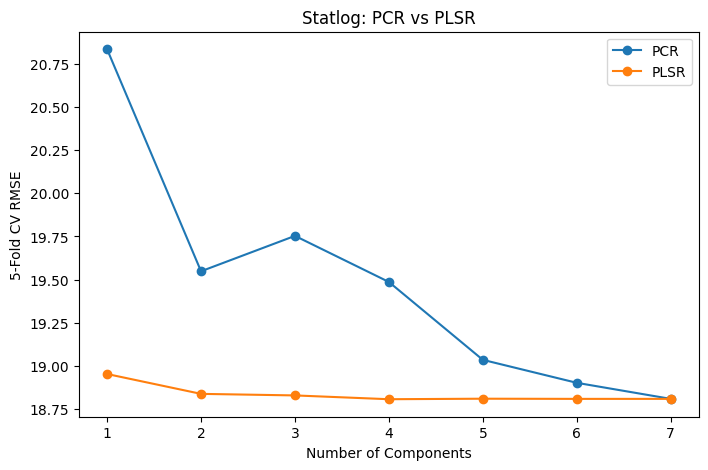

In [61]:
plot_component_comparison(
    heart_pcr_components,
    heart_plsr_components,
    "Statlog"
)

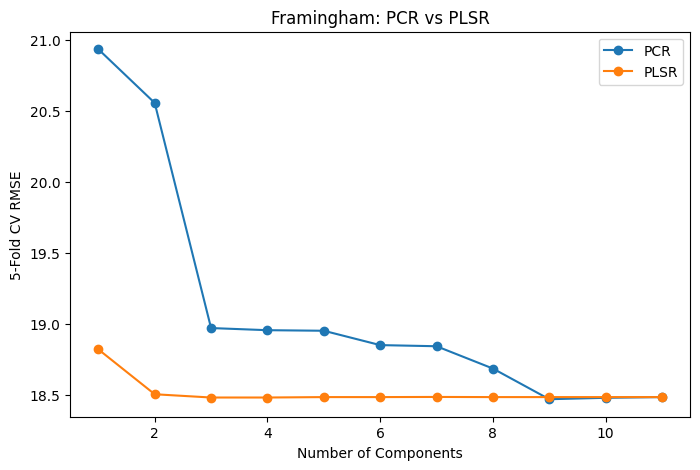

In [62]:
plot_component_comparison(
    framingham_pcr_components,
    framingham_plsr_components,
    "Framingham"
)

## Week 3 Model Summary

The table below summarizes the testing performance of forward selection, backward selection,
PCR, and PLSR for each dataset.

In [63]:
week3_summary = pd.DataFrame([

    {
        "Dataset": "Statlog",
        "Method": "Forward Selection",
        "Features / Components": len(
            heart_forward_features
        ),
        "Testing R²": heart_forward_evaluation[
            "Testing R²"
        ],
        "Testing RMSE": heart_forward_evaluation[
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Statlog",
        "Method": "Backward Selection",
        "Features / Components": len(
            heart_backward_features
        ),
        "Testing R²": heart_backward_evaluation[
            "Testing R²"
        ],
        "Testing RMSE": heart_backward_evaluation[
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Statlog",
        "Method": "PCR",
        "Features / Components": int(
            heart_pcr_results.loc[
                0,
                "Best Components"
            ]
        ),
        "Testing R²": heart_pcr_results.loc[
            0,
            "Testing R²"
        ],
        "Testing RMSE": heart_pcr_results.loc[
            0,
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Statlog",
        "Method": "PLSR",
        "Features / Components": int(
            heart_plsr_results.loc[
                0,
                "Best Components"
            ]
        ),
        "Testing R²": heart_plsr_results.loc[
            0,
            "Testing R²"
        ],
        "Testing RMSE": heart_plsr_results.loc[
            0,
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Framingham",
        "Method": "Forward Selection",
        "Features / Components": len(
            framingham_forward_features
        ),
        "Testing R²": framingham_forward_evaluation[
            "Testing R²"
        ],
        "Testing RMSE": framingham_forward_evaluation[
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Framingham",
        "Method": "Backward Selection",
        "Features / Components": len(
            framingham_backward_features
        ),
        "Testing R²": framingham_backward_evaluation[
            "Testing R²"
        ],
        "Testing RMSE": framingham_backward_evaluation[
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Framingham",
        "Method": "PCR",
        "Features / Components": int(
            framingham_pcr_results.loc[
                0,
                "Best Components"
            ]
        ),
        "Testing R²": framingham_pcr_results.loc[
            0,
            "Testing R²"
        ],
        "Testing RMSE": framingham_pcr_results.loc[
            0,
            "Testing RMSE"
        ]
    },

    {
        "Dataset": "Framingham",
        "Method": "PLSR",
        "Features / Components": int(
            framingham_plsr_results.loc[
                0,
                "Best Components"
            ]
        ),
        "Testing R²": framingham_plsr_results.loc[
            0,
            "Testing R²"
        ],
        "Testing RMSE": framingham_plsr_results.loc[
            0,
            "Testing RMSE"
        ]
    }

]).round(3)

display(week3_summary)

,Dataset,Method,Features / Components,Testing R²,Testing RMSE
0,Statlog,Forward Selection,5,0.184,21.797
1,Statlog,Backward Selection,5,0.184,21.797
2,Statlog,PCR,7,0.198,21.616
3,Statlog,PLSR,4,0.198,21.606
4,Framingham,Forward Selection,7,0.259,18.691
5,Framingham,Backward Selection,7,0.259,18.691
6,Framingham,PCR,9,0.259,18.693
7,Framingham,PLSR,4,0.259,18.685


## Forward and Backward Selection Interpretation

For the Statlog dataset, forward and backward selection independently arrived at the same five-predictor
model consisting of age, sex, resting blood pressure, exercise-induced angina, and ST depression.

The selected model achieved a testing R² of approximately 0.184 and a testing RMSE of approximately
21.797. The full seven-predictor linear model achieved a slightly higher testing R² of approximately
0.198 and a lower RMSE of approximately 21.616.

Therefore, feature selection simplified the Statlog model from seven predictors to five, but this
simplification came with a small decrease in held-out predictive performance. Cholesterol and fasting
blood sugar were removed by the selection process.

For the Framingham dataset, forward and backward selection also converged on the same preferred
subset. Seven of the eleven predictors were retained: male, age, blood-pressure medication use, total
cholesterol, BMI, heart rate, and glucose.

The reduced model achieved a testing R² of approximately 0.259 and RMSE of approximately 18.691,
which was almost identical to the full eleven-predictor model.

This suggests that current smoking status, cigarettes per day, prevalent stroke, and diabetes added
little predictive value for systolic blood pressure within this particular linear model. Framingham
therefore benefited more clearly from feature selection because model complexity was reduced with
almost no loss in testing performance.

## PCR Interpretation

For Statlog, cross-validation selected all seven available principal components. The resulting model
achieved a testing R² of 0.198 and testing RMSE of 21.616.

Because PCR required all seven components, it did not provide meaningful dimensionality reduction for
this dataset. Removing components caused cross-validation performance to worsen.

For Framingham, PCR selected nine of the eleven possible components. The resulting testing R² was
0.259 and testing RMSE was 18.693.

Therefore, PCR was able to remove two dimensions from the Framingham predictor space while maintaining
almost the same predictive performance as the full linear model. However, the reduction was relatively
modest.

These results illustrate a limitation of PCR: principal components are chosen according to predictor
variance rather than their direct usefulness for predicting the outcome.

## PLSR Interpretation

PLSR produced substantially greater dimensionality reduction than PCR.

For Statlog, cross-validation selected four PLS components rather than the seven components selected
by PCR. The four-component PLSR model achieved a testing R² of approximately 0.198 and testing RMSE
of 21.606, essentially matching the performance of the full linear model.

For Framingham, PLSR also selected only four components. Despite reducing eleven original predictors
to four components, testing R² remained approximately 0.259 and RMSE was approximately 18.685.

Therefore, PLSR preserved nearly all of the predictive performance of the original models while using
far fewer dimensions. This suggests that components constructed with knowledge of the outcome were
more efficient for these datasets than components based only on predictor variance.

## PCR vs PLSR Interpretation

The component-selection results show an important difference between PCR and PLSR.

PCR required all seven components for Statlog and nine of eleven components for Framingham to achieve
its best cross-validation performance.

PLSR required only four components for both datasets while producing nearly identical held-out
performance.

This difference is consistent with the design of the two approaches. PCR chooses components that
explain variation in the predictors without considering the target. PLSR constructs components while
also considering their relationship with the outcome.

For these cardiovascular datasets, the directions containing the most predictor variance were not
necessarily the directions most useful for prediction. PLSR therefore provided more efficient
dimensionality reduction.

## Expected and Unexpected Findings

It was expected that removing weak predictors could simplify the regression models, but the extent of
the differences between datasets was notable.

For Statlog, forward and backward selection both identified the same five predictors, yet the reduced
model performed slightly worse on the held-out test set than the full model. Therefore, fewer predictors
did not automatically result in better prediction.

For Framingham, four predictors could be removed with virtually no change in testing performance. This
suggests that several variables provided little additional information for predicting systolic blood pressure
after the stronger predictors were already included.

Another notable finding was the difference between PCR and PLSR. PCR retained most or all available
components, whereas PLSR needed only four components in both datasets to preserve nearly identical
predictive performance. This was stronger dimensionality reduction than might have been expected from PCR.

## Relationship to Previous Exploratory Data Analysis

Previous exploratory analysis in Module B helped identify several potentially important cardiovascular
variables before formal feature selection was performed.

In Statlog, earlier analysis highlighted relationships involving age, exercise-related variables, maximum
heart rate, blood pressure, and ST depression. Week 3 feature selection retained age, exercise-induced
angina, resting blood pressure, and ST depression, which is broadly consistent with those earlier findings.

In Framingham, previous analysis highlighted age, BMI, blood pressure, cholesterol, glucose, and related
clinical measures. Many of these variables were retained by both forward and backward selection.

However, the Week 3 modeling also demonstrates why exploratory relationships should not automatically be
treated as predictive importance. Some variables that appear meaningful individually may contribute little
additional information after other predictors are already included in the model.

## Metrics, Model Selection, and Overfitting

The primary model-selection metric used in Week 3 was 5-fold cross-validation RMSE.

RMSE measures the typical magnitude of prediction error, with lower values indicating better predictive
performance. Cross-validation was used during feature and component selection so that decisions were not
based only on training fit.

R² and RMSE were then calculated on a separate held-out test set. Testing R² measures how much variation
in previously unseen outcomes is explained by the model, while testing RMSE measures the magnitude of
prediction error on unseen observations.

To reduce the risk of overfitting and data leakage, the test set was separated before feature selection.
Forward selection, backward selection, PCR component selection, and PLSR component selection were carried
out using training data and cross-validation. The test set was reserved for final evaluation.

For PCR and PLSR, the number of retained components acts as a model-complexity parameter. Keeping too many
components may retain unnecessary complexity, while keeping too few can cause underfitting and discard useful
predictive information.

## When These Methods Are Appropriate

Forward and backward selection are useful when interpretability is important and the goal is to identify a
smaller subset of the original predictors. A limitation is that these methods follow a step-by-step path and
do not examine every possible combination of predictors, so they are not guaranteed to identify the globally
best subset.

PCR is useful when many predictors are correlated or when dimensionality needs to be reduced. However, PCA
constructs components without considering the outcome, so a high-variance component is not necessarily useful
for prediction.

PLSR is useful when dimensionality reduction and prediction are both important because its components are
constructed using information from both the predictors and outcome. Its disadvantage is that the resulting
components are combinations of several original variables and are therefore less directly interpretable than
a model using the original predictors.

For this project, stepwise selection was more useful for identifying interpretable individual predictors,
while PLSR was more effective when the goal was aggressive dimensionality reduction without sacrificing
predictive performance.

# Week 3 Overall Conclusion

Week 3 compared two feature-selection methods and two dimensionality-reduction approaches across the Statlog
Heart Disease and Framingham Heart Study datasets.

Forward and backward selection independently converged on the same preferred feature subsets within each
dataset. For Statlog, five of seven predictors were retained, but the reduced model performed slightly worse
on the held-out test set than the full linear regression model. This suggests that feature selection improved
simplicity and interpretability but did not improve predictive accuracy.

For Framingham, seven of eleven predictors were retained with virtually no reduction in test performance.
This demonstrates that several predictors could be removed while preserving nearly the same ability to predict
systolic blood pressure.

PCR provided relatively little dimensionality reduction. Statlog required all seven principal components,
while Framingham required nine of eleven components.

PLSR was considerably more efficient. Only four components were selected for both datasets, yet test
performance remained nearly identical to the full linear models. This suggests that incorporating the outcome
while constructing components allowed PLSR to preserve predictive information more efficiently than PCR.

Overall, no single feature-reduction strategy was universally superior. Stepwise selection offered greater
interpretability because it retained original variables, while PLSR provided the strongest dimensionality
reduction. The results demonstrate that model choice should depend on whether the priority is prediction,
interpretability, or reducing dimensionality.

## AI Use Disclosure

ChatGPT was used as an assistive tool to help organize and articulate formal written interpretations after
the analysis had been performed and the models had been run. The underlying dataset analysis, model execution,
outputs, and numerical results were generated in the Jupyter Notebook and then interpreted with AI assistance
for clarity and presentation.